# 09 — Full model and SHAP

**Questions:** Does a more flexible model (XGBoost) predict which trials fail to enroll better than notebook 05's
logistic regression? And once trial design and disease area are accounted for, which eligibility rules push the
predicted risk up the most?

Everything is set up to match notebook 05: the same labeled trials, the same features, training on trials that
started 2008–2016 and testing on 2017–2020, and PR-AUC as the main metric. The comparison uses 05's saved predictions
on the same test trials.

**Labels are still v0**, the keyword stop-reason rules. Once notebook 07's validated labels replace them, rerun 05
and then this notebook.

**Inputs:** `trials.parquet`, plus files written by earlier notebooks: `eligibility_features.parquet` (03),
`disease_area.parquet` (04) and `baseline_predictions.parquet` (05). Run those notebooks first.

## 1. Setup

In [1]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import xgboost as xgb
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "notebooks" / "figures"
GROUP_COLORS = {"design": "#2a78d6", "disease area": "#eb6834", "eligibility": "#1baf7a"}

trials = pd.read_parquet(ROOT / "data/processed/trials.parquet")
elig = pd.read_parquet(ROOT / "data/processed/eligibility_features.parquet")
area = pd.read_parquet(ROOT / "data/processed/disease_area.parquet")
baseline = pd.read_parquet(ROOT / "data/processed/baseline_predictions.parquet")

df = trials[trials["label"].notna()].merge(elig, on="nct_id", how="left").merge(area, on="nct_id", how="left")
df["label"] = df["label"].astype(int)
print(len(df), "labeled trials, failure rate:", round(df["label"].mean() * 100, 2), "%")

164593 labeled trials, failure rate: 4.79 %


## 2. Features

The feature groups are the same as notebook 05's (the code is copied from there, so change both if one changes).
Two things differ because of the model:

- XGBoost splits on categories directly, so there is no one-hot encoding, and each categorical feature gets a
  single SHAP value.
- XGBoost handles missing numbers itself, so nothing is imputed. A blank maximum age still means no upper limit,
  and `has_max_age` says so.

In [2]:
UNIT_TO_YEARS = {"year": 1, "month": 1/12, "week": 1/52.18, "day": 1/365.25, "hour": 1/8766, "minute": 1/525960}

def age_years(s):
    if not isinstance(s, str):
        return np.nan
    m = re.match(r"\s*([\d.]+)\s*([a-z]+?)s?\s*$", s.lower())
    if not m or m.group(2) not in UNIT_TO_YEARS:
        return np.nan
    return float(m.group(1)) * UNIT_TO_YEARS[m.group(2)]

df["min_age_yrs"] = df["minimum_age"].map(age_years)
df["max_age_yrs"] = df["maximum_age"].map(age_years)
df["has_max_age"] = df["maximum_age"].notna().astype(int)
df["n_collaborators"] = df["n_collaborators"].fillna(0)

DESIGN_CAT = ["phase", "lead_sponsor_class", "primary_purpose", "allocation", "masking",
              "intervention_model", "gender", "healthy_volunteers", "has_dmc"]
DESIGN_NUM = ["number_of_arms", "n_conditions", "n_interventions", "n_collaborators",
              "min_age_yrs", "max_age_yrs", "has_max_age"]
AREA_CAT = ["primary_area", "area_source"]
AREA_NUM = [c for c in area.columns if c.startswith("area_") and c != "area_source"] + ["n_areas"]
ELIG_NUM = ["criteria_n_chars", "n_inclusion", "n_exclusion", "n_rule_types"] + \
           [c for c in elig.columns if c.startswith("rule_")]
RULES = [c for c in ELIG_NUM if c.startswith("rule_")]

df[AREA_NUM + ELIG_NUM] = df[AREA_NUM + ELIG_NUM].astype(float)
for col in DESIGN_CAT + AREA_CAT:
    df[col] = df[col].astype("object").fillna("missing").astype(str).astype("category")

FEATURES = {
    "B. Design + disease area": DESIGN_CAT + AREA_CAT + DESIGN_NUM + AREA_NUM,
    "C. Design + disease + eligibility": DESIGN_CAT + AREA_CAT + DESIGN_NUM + AREA_NUM + ELIG_NUM,
}
GROUP = {**{c: "design" for c in DESIGN_CAT + DESIGN_NUM}, **{c: "disease area" for c in AREA_CAT + AREA_NUM},
         **{c: "eligibility" for c in ELIG_NUM}}

## 3. Train, validation and test split

Training and test years are the same as in 05. For tuning, the last two training years (2015–2016) are held out as
a validation set, so settings are chosen the same way the model is used: fit on older trials, judged on newer ones.

In [3]:
train = df[df["start_year"] <= 2016]
test = df[df["start_year"] >= 2017]
inner = train[train["start_year"] <= 2014]
valid = train[train["start_year"] >= 2015]
for name, d in [("train 2008-2016", train), ("  fit 2008-2014", inner), ("  validation 2015-2016", valid),
                ("test 2017-2020", test)]:
    print(f"{name:24} {len(d):7,} trials, {d['label'].sum():5,} failures")

train 2008-2016          106,860 trials, 5,073 failures
  fit 2008-2014           78,734 trials, 3,796 failures
  validation 2015-2016    28,126 trials, 1,277 failures
test 2017-2020            57,733 trials, 2,813 failures


## 4. Tuning

A small grid over tree depth and the minimum size of a leaf, with a learning rate of 0.05. For each setting, trees
are added until PR-AUC on the validation years hasn't improved for 50 rounds. Each feature set is tuned separately,
so model C's eligibility features don't get an unfair advantage. Then each model is refit on all 2008–2016 trials
with its best setting. The differences between settings are small, so the exact choice matters little.

In [4]:
GRID = [{"max_depth": d, "min_child_weight": w} for d in [3, 6] for w in [1, 20]]
BASE = dict(learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, tree_method="hist", enable_categorical=True,
            max_cat_to_onehot=1, n_jobs=-1, random_state=0)

def tune(cols):
    rows = []
    for params in GRID:
        m = xgb.XGBClassifier(n_estimators=2000, eval_metric="aucpr", early_stopping_rounds=50, **BASE, **params)
        m.fit(inner[cols], inner["label"], eval_set=[(valid[cols], valid["label"])], verbose=False)
        p = m.predict_proba(valid[cols])[:, 1]
        rows.append({**params, "trees": m.best_iteration + 1, "validation PR-AUC": average_precision_score(valid["label"], p)})
    return pd.DataFrame(rows).sort_values("validation PR-AUC", ascending=False, ignore_index=True)

tuning = {name: tune(cols) for name, cols in FEATURES.items()}
pd.concat(tuning).round(4)

max_depth  min_child_weight  trees  \
B. Design + disease area          0          6                 1     59   
                                  1          6                20     66   
                                  2          3                20    224   
                                  3          3                 1    220   
C. Design + disease + eligibility 0          6                 1     80   
                                  1          3                20    200   
                                  2          6                20    110   
                                  3          3                 1    193   

                                     validation PR-AUC  
B. Design + disease area          0             0.1139  
                                  1             0.1121  
                                  2             0.1112  
                                  3             0.1110  
C. Design + disease + eligibility 0             0.1251  
                                  1             0.1226  
                                  2             0.1224  
                                  3             0.1221

In [5]:
models = {}
for name, cols in FEATURES.items():
    best = tuning[name].iloc[0]
    models[name] = xgb.XGBClassifier(n_estimators=int(best["trees"]), max_depth=int(best["max_depth"]),
                                     min_child_weight=int(best["min_child_weight"]), **BASE)
    models[name].fit(train[cols], train["label"])
    print(f"{name}: depth {int(best['max_depth'])}, min_child_weight {int(best['min_child_weight'])}, "
          f"{int(best['trees'])} trees")

B. Design + disease area: depth 6, min_child_weight 1, 59 trees


C. Design + disease + eligibility: depth 6, min_child_weight 1, 80 trees


## 5. Test-set results

Same metrics as 05, plus the failure rate among the 10% of test trials each model ranks riskiest. That's the number
that matters if the model is used to flag trials for a closer look.

In [6]:
out = test[["nct_id", "label"]].merge(baseline.drop(columns="start_year"), on="nct_id", how="left",
                                      suffixes=("", "_05"))
assert out["pred_C"].notna().all() and out["label"].eq(out["label_05"]).all(), \
    "Test trials or labels differ from notebook 05's saved predictions: rerun 05 first."
y_test = out["label"].to_numpy()

preds = {f"logistic {k} (05)": out[f"pred_{k}"].to_numpy() for k in "ABC"}
for name, cols in FEATURES.items():
    preds[f"XGBoost {name[0]}"] = models[name].predict_proba(test[cols])[:, 1]

def top_decile_rate(y, p):
    return y[p >= np.quantile(p, 0.9)].mean()

results = pd.DataFrame({
    name: {"PR-AUC": average_precision_score(y_test, p), "ROC-AUC": roc_auc_score(y_test, p),
           "Brier": brier_score_loss(y_test, p), "failure rate in top 10%": top_decile_rate(y_test, p)}
    for name, p in preds.items()
}).T
results.loc["Random guess"] = [y_test.mean(), 0.5, np.nan, y_test.mean()]
results.round(4)

,PR-AUC,ROC-AUC,Brier,failure rate in top 10%
logistic A (05),0.1100,0.7021,0.0451,0.1320
logistic B (05),0.1151,0.7088,0.0449,0.1363
logistic C (05),0.1217,0.7170,0.0448,0.1451
XGBoost B,0.1241,0.7261,0.0447,0.1460
XGBoost C,0.1312,0.7383,0.0445,0.1502
Random guess,0.0487,0.5000,NaN,0.0487


To check that the differences aren't luck, the test set is resampled 1,000 times as in 05. If the 95% interval for
a gain stays above zero, the gain is real.

In [7]:
rng = np.random.default_rng(42)

def bootstrap_gain(p_base, p_new, n_boot=1000):
    gains = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_test), len(y_test))
        gains.append(average_precision_score(y_test[idx], p_new[idx]) -
                     average_precision_score(y_test[idx], p_base[idx]))
    actual = average_precision_score(y_test, p_new) - average_precision_score(y_test, p_base)
    return pd.Series({"gain": actual, "lo": np.percentile(gains, 2.5), "hi": np.percentile(gains, 97.5)})

pd.DataFrame({
    "XGBoost C vs logistic C (model)": bootstrap_gain(preds["logistic C (05)"], preds["XGBoost C"]),
    "XGBoost C vs XGBoost B (eligibility)": bootstrap_gain(preds["XGBoost B"], preds["XGBoost C"]),
}).T.round(4)

,gain,lo,hi
XGBoost C vs logistic C (model),0.0095,0.0038,0.0150
XGBoost C vs XGBoost B (eligibility),0.0072,0.0029,0.0117


## 6. What the model relies on (SHAP)

For each test trial, SHAP splits the model's prediction into one contribution per feature. The contributions add up
to the trial's predicted log-odds of failure, so a positive value means the feature pushed this trial's risk up and
a negative value means it pushed it down. XGBoost computes exact SHAP values for its own trees
(`pred_contribs=True`), so no extra package is needed.

These values show what the model leans on, not what causes failure.

In [8]:
COLS = FEATURES["C. Design + disease + eligibility"]
model = models["C. Design + disease + eligibility"]
contrib = model.get_booster().predict(xgb.DMatrix(test[COLS], enable_categorical=True), pred_contribs=True)
shap = pd.DataFrame(contrib[:, :-1].astype(float), columns=COLS, index=test.index)
importance = shap.abs().mean().sort_values(ascending=False)
importance_by_group = importance.groupby(importance.index.map(GROUP)).sum()
print("Share of total mean |SHAP| by feature group:")
print((importance_by_group / importance_by_group.sum() * 100).round(1).sort_values(ascending=False).to_string())

Share of total mean |SHAP| by feature group:
design          60.1
eligibility     21.3
disease area    18.6


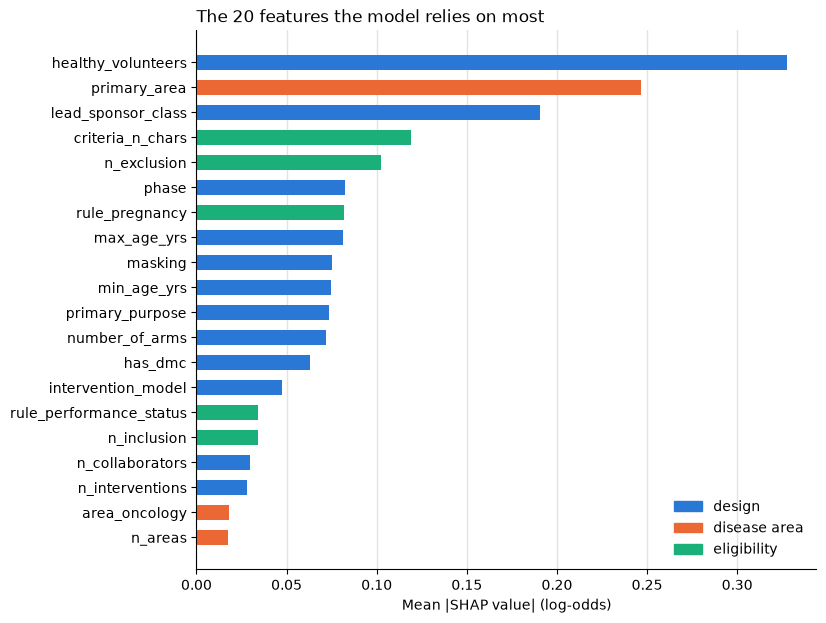

In [9]:
top = importance.head(20)[::-1]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top.index, top, height=0.6, color=[GROUP_COLORS[GROUP[c]] for c in top.index])
ax.set_xlabel("Mean |SHAP value| (log-odds)")
ax.set_title("The 20 features the model relies on most", loc="left")
ax.legend(handles=[Patch(color=c, label=g) for g, c in GROUP_COLORS.items()], frameon=False, loc="lower right")
ax.grid(axis="x", color="#e4e3df", lw=1)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.savefig(FIG / "full_model_shap_importance.png", bbox_inches="tight", dpi=110)
plt.show()

## 7. The riskiest eligibility rules

For each rule type from notebook 03, the table compares the rule's average SHAP value in test trials that have the
rule with those that don't. The last column turns the gap into a change in the predicted odds of failure: +10%
means the model typically predicts about 10% higher odds of failure for trials with the rule than for trials
without it, after accounting for design, disease area and the other rules. Raw failure rates are shown for
comparison; they don't account for anything else.

In [10]:
rows = {}
for r in RULES:
    has = test[r].eq(1)
    rows[r.removeprefix("rule_")] = {
        "test trials with rule": int(has.sum()),
        "mean SHAP with rule": shap.loc[has, r].mean(),
        "mean SHAP without": shap.loc[~has, r].mean(),
        "failure rate with rule (%)": test.loc[has, "label"].mean() * 100,
        "failure rate without (%)": test.loc[~has, "label"].mean() * 100,
    }
rule_table = pd.DataFrame(rows).T
rule_table["change in odds, with vs without (%)"] = \
    (np.exp(rule_table["mean SHAP with rule"] - rule_table["mean SHAP without"]) - 1) * 100
rule_table = rule_table.sort_values("change in odds, with vs without (%)", ascending=False)
rule_table.round(2)

,test trials with rule,mean SHAP with rule,mean SHAP without,failure rate with rule (%),failure rate without (%),"change in odds, with vs without (%)"
pregnancy,28386.0,0.06,-0.10,6.40,3.40,17.76
performance_status,5123.0,0.14,-0.02,12.65,4.12,17.37
lab_threshold,7882.0,0.01,-0.01,9.55,4.13,2.04
prior_malignancy,3244.0,0.01,-0.00,7.86,4.69,1.11
concomitant_meds,6943.0,0.01,-0.00,8.11,4.43,0.97
cardiac,9610.0,0.01,-0.00,7.60,4.33,0.65
prior_therapy,4071.0,0.01,-0.00,11.18,4.39,0.63
language_consent,11924.0,0.00,0.00,4.90,4.87,0.25
organ_function,9594.0,0.00,-0.00,9.21,4.01,0.20
infection,10159.0,-0.02,0.00,6.90,4.44,-1.91


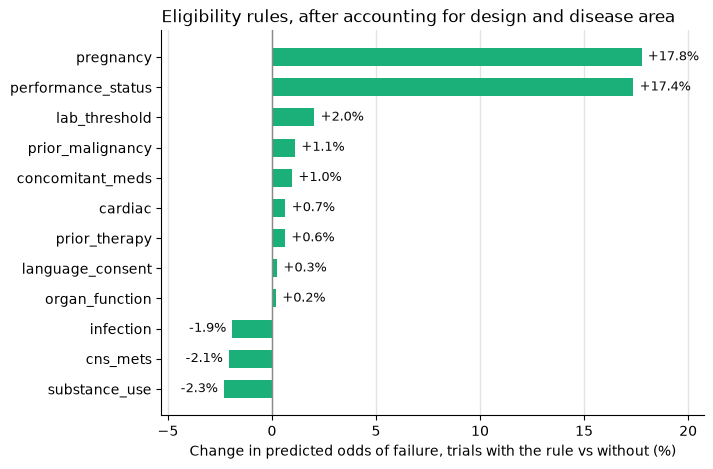

In [11]:
fig, ax = plt.subplots(figsize=(7, 5))
y = rule_table["change in odds, with vs without (%)"][::-1]
ax.barh(y.index, y, height=0.6, color=GROUP_COLORS["eligibility"])
for i, v in enumerate(y):
    ax.text(v + (0.3 if v >= 0 else -0.3), i, f"{v:+.1f}%", va="center", ha="left" if v >= 0 else "right",
            fontsize=9, color="#0b0b0b")
ax.axvline(0, color="#8a8984", lw=1)
ax.set_xlim(min(y.min(), 0) - 3, y.max() + 3)
ax.set_xlabel("Change in predicted odds of failure, trials with the rule vs without (%)")
ax.set_title("Eligibility rules, after accounting for design and disease area", loc="left")
ax.grid(axis="x", color="#e4e3df", lw=1)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.savefig(FIG / "full_model_rule_effects.png", bbox_inches="tight", dpi=110)
plt.show()

The number of exclusion criteria is the eligibility feature the model uses most. The plot shows how its
contribution changes with the count: each dot is a test trial, and the line is the average at each count.

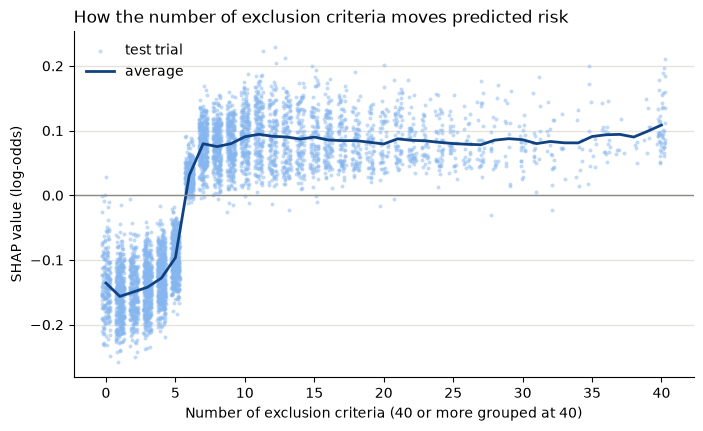

In [12]:
x = test["n_exclusion"].clip(upper=40)
s = shap["n_exclusion"]
dots = np.random.default_rng(0).choice(len(test), 5000, replace=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(x.iloc[dots] + np.random.default_rng(1).uniform(-0.3, 0.3, len(dots)), s.iloc[dots],
           s=8, color="#86b6ef", alpha=0.5, linewidths=0, label="test trial")
mean = s.groupby(x).mean()
ax.plot(mean.index, mean, color="#104281", lw=2, label="average")
ax.axhline(0, color="#8a8984", lw=1)
ax.set_xlabel("Number of exclusion criteria (40 or more grouped at 40)")
ax.set_ylabel("SHAP value (log-odds)")
ax.set_title("How the number of exclusion criteria moves predicted risk", loc="left")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", color="#e4e3df", lw=1)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.savefig(FIG / "full_model_exclusion_count.png", bbox_inches="tight", dpi=110)
plt.show()

## 8. Rules within disease areas

Notebook 04 found that disease area affects both how strict trials are and how often they fail. This table repeats
the comparison above (change in predicted odds, %, trials with the rule vs without) separately within each of the
largest disease areas. Cells with fewer than 100 test trials that have the rule are left blank.

In [13]:
areas = test["primary_area"].value_counts()
areas = [a for a in areas[areas >= 1000].index if a != "unclassified"]
by_area = {}
for r in RULES:
    g = shap[r].groupby([test["primary_area"], test[r].eq(1)], observed=True)
    mean, n = g.mean().unstack(), g.size().unstack()
    by_area[r.removeprefix("rule_")] = ((np.exp(mean[True] - mean[False]) - 1) * 100).where(n[True] >= 100)
by_area = pd.DataFrame(by_area).T[areas]
by_area.round(1)

primary_area,oncology,infectious,mental_health,metabolic_endocrine,cardiovascular,symptoms_other,eye_ent_oral,neurology,behavioral,healthy,musculoskeletal,respiratory,skin_connective,digestive,renal_urologic
organ_function,0.1,0.3,0.1,0.3,0.2,0.3,NaN,0.2,NaN,0.4,0.1,0.2,0.3,0.3,0.2
lab_threshold,2.9,1.7,1.3,1.3,2.5,1.5,NaN,2.0,NaN,1.1,1.4,1.5,1.7,2.3,2.4
prior_malignancy,0.9,1.7,NaN,1.0,NaN,NaN,NaN,NaN,NaN,3.0,0.5,0.8,0.7,NaN,NaN
prior_therapy,0.5,0.9,NaN,0.7,NaN,NaN,NaN,NaN,NaN,NaN,0.6,NaN,0.8,NaN,NaN
performance_status,16.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pregnancy,13.6,20.0,24.1,16.2,17.2,21.3,17.1,16.8,21.5,11.0,20.6,19.5,14.7,15.6,17.9
infection,-1.8,-2.1,-2.6,-3.1,-2.0,-1.3,-1.9,-2.2,-2.0,-2.2,-1.5,-1.7,-1.8,-1.4,-2.1
cardiac,0.3,0.6,1.2,0.7,0.6,0.7,NaN,0.6,1.9,1.0,1.0,1.0,NaN,0.5,0.4
cns_mets,-2.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
language_consent,-0.4,0.6,0.6,0.5,-0.3,0.1,0.4,-0.0,0.7,1.0,0.9,0.4,0.2,0.8,0.3


## 9. Save predictions and model

Test-set predictions go next to 05's so later notebooks can compare on the same trials. The fitted model C is saved for
the Streamlit tool.

In [14]:
saved = out[["nct_id", "label"]].assign(start_year=test["start_year"].to_numpy(),
                                        pred_xgb_B=preds["XGBoost B"], pred_xgb_C=preds["XGBoost C"])
saved.to_parquet(ROOT / "data/processed/full_model_predictions.parquet", index=False)
model.save_model(str(ROOT / "data/processed/full_model.json"))

## 10. Findings so far (v0 labels)

These numbers will change once the validated stop reasons replace v0.

**Model**
- XGBoost with all three feature groups reaches a test PR-AUC of 0.131, against 0.122 for 05's logistic model C
  (gain 0.0095, 95% CI 0.004–0.015), and a ROC-AUC of 0.738 against 0.717. Among the 10% of test trials it ranks
  riskiest, 15.0% failed, about three times the overall rate of 4.9%.
- Eligibility features still help in the more flexible model: adding them raises PR-AUC by 0.0072 (95% CI
  0.003–0.012), about the same gain as in 05. The gains are real but small; most of what the model knows comes from
  design.
- Design features account for 60% of the total SHAP importance, eligibility features 21% and disease area 19%. The
  top features are healthy volunteers, disease area, sponsor class, the length of the criteria text and the number
  of exclusion criteria.

**Eligibility rules**
- Two rules stand out. Excluding pregnant participants raises the predicted odds of failure by about 18%, and
  requiring a minimum performance status by about 17%. The pregnancy effect appears in every large disease area
  (from +11% in healthy-volunteer trials to +24% in mental health). Performance-status rules are almost all in
  oncology trials, so that's the only area where they can be checked. Every other rule type moves the odds by 2%
  or less.
- The number of exclusion criteria works like a threshold: trials with 5 or fewer have lower predicted risk, there
  is a sharp rise between 5 and 7, and more criteria beyond that add little. Part of this may reflect which kinds of
  trials have very short criteria lists, not the criteria themselves.
- These results agree with the other notebooks: 05's logistic model also gives pregnancy restrictions and more
  exclusion criteria higher risk, and notebook 10 finds both raise the hazard of termination for low enrollment
  specifically (HR 1.26 for excluding pregnancy; 1.10 per doubling of exclusion criteria), not termination for
  other reasons.

## 11. Still to do

1. After notebook 07's validated labels replace v0, rerun 05 and then this notebook, and rewrite section 10.
2. Add the LLM eligibility features from notebook 11 when they're ready.